<a href="https://colab.research.google.com/github/Ariqq16/PCVK_Ganjil_2026/blob/main/P7/D2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!apt-get -qq update
!apt-get -qq install tesseract-ocr tesseract-ocr-ind
!pip -q install pytesseract

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import pytesseract
from pytesseract import Output
import os

pytesseract.pytesseract.tesseract_cmd = r'/usr/bin/tesseract'

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


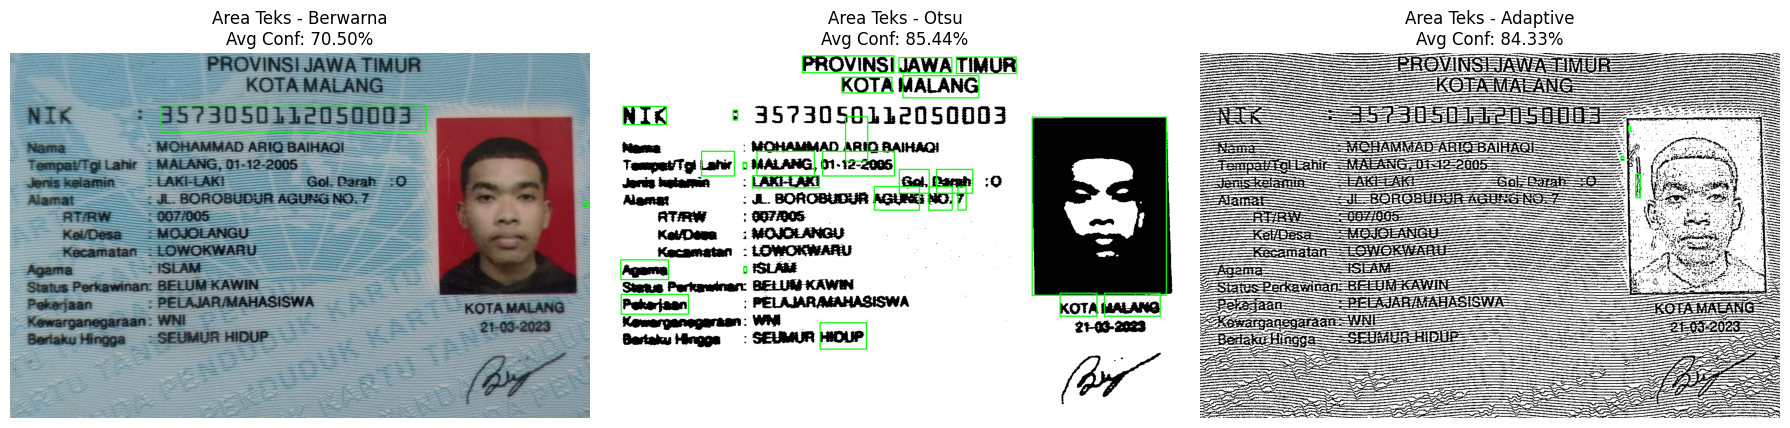

--- HASIL OCR (BERWARNA) ---
So ee” — MOMMAANG

Aa “5 Aa

NIK: 3573050112050003 $

Pa EA —— |
— Kecamatan 2 LOWOKWARY ——————-—— ———

Memarganegaraan: WNP- ——— —— 52 sena
--- HASIL OCR (OTSU) ---
PROVINSI JAWA TIMUR
KOTA MALANG

NIK : 357305011205099593
yaa . MOMAMAD AR DAMAI 3
TampatTgi Lahir : MALANG, 01-12-2005
Jeris kelamin: LAKI-LAKI Gol. Darah 10
Mama 1 JL. BOROBUDYA AGURG NO. 7

ATAW ——: S0TANS

Kel/Dasa —: MOJOLANGU
Agama 1 #SLAKE
Pekerjaan : PELAJARASAHABISWA KOTA MALANG
Bertaku Hingga: SEUMUR HIDUP 21-09-2023
--- HASIL OCR (ADAPTIVE) ---
AA TA ea IA AE
PA KP TEE AN 5
AP
————————-6555— TES
Sa ES MH FEE AA BATA
1, ee Er FEE DPS memaamn AS
& AA 5 AS 5 gi | . Ol, FE
AA ee BN Aa . Pan
AN Ke YAMMAD AE BAIHAG——- Pa an N
-— Aa aman : Pp ea Meat NO SES
TE ——A PA ————-— ———y5— Se Pap pads Yuna AG 5
AS AN NN
ee — ne A | Sa ai M Ka
Pe aa AN EA Ea MN apn un Bag 5
Aan JR Reg AE EN SI pa Na Zi 5
PA Ah ane Masa Tar 3
-—— He 5eI0S —— 2 ———- he NB bni P3 aa P5
Pp AKI - SA hn Ae FS
Kej b esa He 

In [4]:
BASE_PATH = '/content'

path_ktp = '/content/drive/MyDrive/PCVK_2026/ktp_ariq.jpeg'
img_color = cv.imread(path_ktp)

if img_color is None:
    img_color = cv.imread(os.path.join(BASE_PATH, 'ktp_fulan.jpg'))

if img_color is None:
    print("Warning: Gambar tidak ditemukan. Menggunakan gambar hitam dummy.")
    img_color = np.zeros((300, 400, 3), dtype=np.uint8)

img_rgb = cv.cvtColor(img_color, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img_color, cv.COLOR_BGR2GRAY)

blur = cv.GaussianBlur(img_gray, (5, 5), 0)
_, img_otsu = cv.threshold(blur, 0, 255, cv.THRESH_BINARY + cv.THRESH_OTSU)
img_adaptive = cv.adaptiveThreshold(img_gray, 255, cv.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv.THRESH_BINARY, 11, 2)
images_dict = {
    'Berwarna': (img_rgb, img_rgb),
    'Otsu': (cv.cvtColor(img_otsu, cv.COLOR_GRAY2RGB), img_otsu),
    'Adaptive': (cv.cvtColor(img_adaptive, cv.COLOR_GRAY2RGB), img_adaptive)
}

ocr_results_text = {}
ocr_confidences = {}

plt.figure(figsize=(18, 6))

for idx, (name, (img_disp, img_proc)) in enumerate(images_dict.items(), 1):
    custom_config = r'--oem 3 --psm 6 -l ind'

    text = pytesseract.image_to_string(img_proc, config=custom_config)
    ocr_results_text[name] = text

    data = pytesseract.image_to_data(img_proc, config=custom_config, output_type=Output.DICT)

    img_bbox = img_disp.copy()
    n_boxes = len(data['text'])
    conf_list = []

    for i in range(n_boxes):
        conf = int(data['conf'][i])
        if conf > 60: # Threshold Confidence > 60%
            conf_list.append(conf)
            x, y, w, h = data['left'][i], data['top'][i], data['width'][i], data['height'][i]
            cv.rectangle(img_bbox, (x, y), (x + w, y + h), (0, 255, 0), 2)

    avg_conf = np.mean(conf_list) if conf_list else 0
    ocr_confidences[name] = avg_conf

    plt.subplot(1, 3, idx)
    plt.imshow(img_bbox)
    plt.title(f"Area Teks - {name}\nAvg Conf: {avg_conf:.2f}%")
    plt.axis('off')

plt.tight_layout()
plt.show()

print("="*60)
for name, txt in ocr_results_text.items():
    print(f"--- HASIL OCR ({name.upper()}) ---")
    print(txt.strip())
    print("="*60)